In [1]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

In [14]:
img = cv2.imread("bird.png")
img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
img = img.astype(np.float32)
img = cv2.resize(img, (224, 224))
# output_img = np.zeros_like(img, dtype=np.float32)
output_img1 = img.copy()
output_img2 = img.copy()

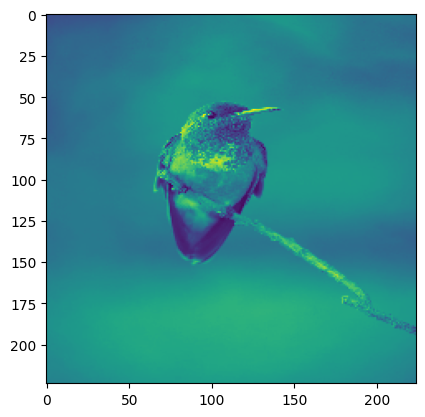

In [15]:
plt.imshow(img)

In [16]:
# finding DoG of this image
# got these gaussian kernels from gpt nothing too complex

gaussian_sigma_0_8 = np.array([
    [0.0571, 0.1248, 0.0571],
    [0.1248, 0.2725, 0.1248],
    [0.0571, 0.1248, 0.0571]
])

# Gaussian kernel with sigma = 1.2
gaussian_sigma_1_2 = np.array([
    [0.0857, 0.1211, 0.0857],
    [0.1211, 0.1713, 0.1211],
    [0.0857, 0.1211, 0.0857]
])


In [17]:
kernel_dim = 3
for i in range(kernel_dim//2, img.shape[0] - kernel_dim):
    for j in range(kernel_dim//2, img.shape[1] - kernel_dim):
        img_slice = img[i:i+kernel_dim, j:j+kernel_dim]
        sub = np.sum(gaussian_sigma_1_2 * img_slice)
        output_img1[i+kernel_dim//2, j+kernel_dim//2] = sub

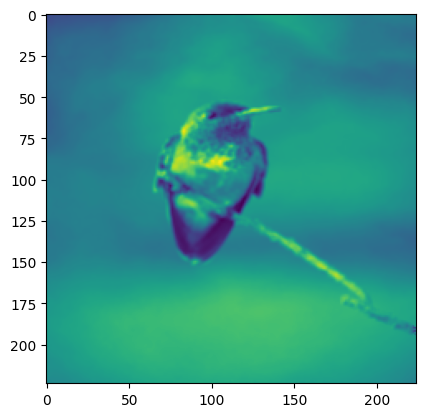

In [18]:
plt.imshow(output_img1)

In [19]:
kernel_dim = 3
for i in range(kernel_dim//2, img.shape[0] - kernel_dim):
    for j in range(kernel_dim//2, img.shape[1] - kernel_dim):
        img_slice = img[i:i+kernel_dim, j:j+kernel_dim]
        sub = np.sum(gaussian_sigma_0_8 * img_slice)
        output_img1[i+kernel_dim//2, j+kernel_dim//2] = sub

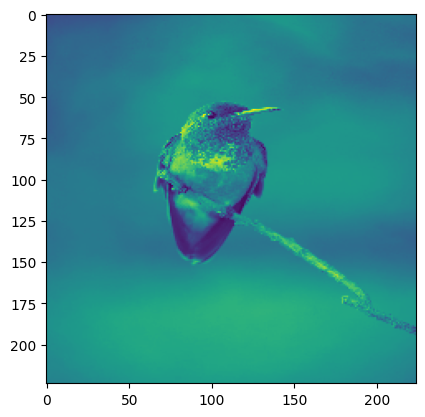

In [20]:
plt.imshow(output_img2)

In [27]:
DoG = output_img2 - output_img1

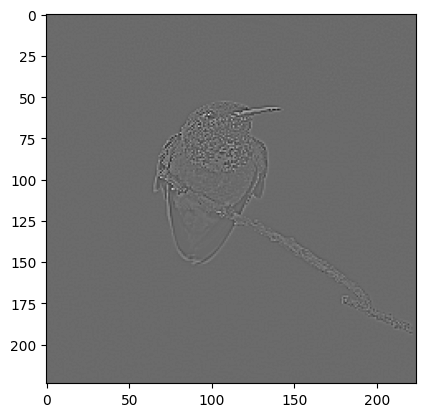

In [28]:
plt.imshow(DoG, cmap="grey")